<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%A0%95%EA%B7%9C%ED%99%94_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

오버피팅이란 모델이 학습 데이터의 불필요한 편향이나 노이즈까지 학습함으로써 모델의 일반화 성능이 떨어지는 상황을 말합니다.

데이터셋과 테스트 데이터셋을 도입하여 모델의 최적화 과정에서 발생할 수 있는 오버피팅을 방지할 수 있습니다.

### 정규화
정규화란 오버피팅을 늦추고 모델이 학습 데이터로부터 적절한 특징(feature)들을 학습하여 일반화 오차를 낮춰줄 수 있는 기법을 말합니다.

일반화된 모델은 노이즈에 더 강한 모델이 됩니다.

### 다양한 정규화 방법들


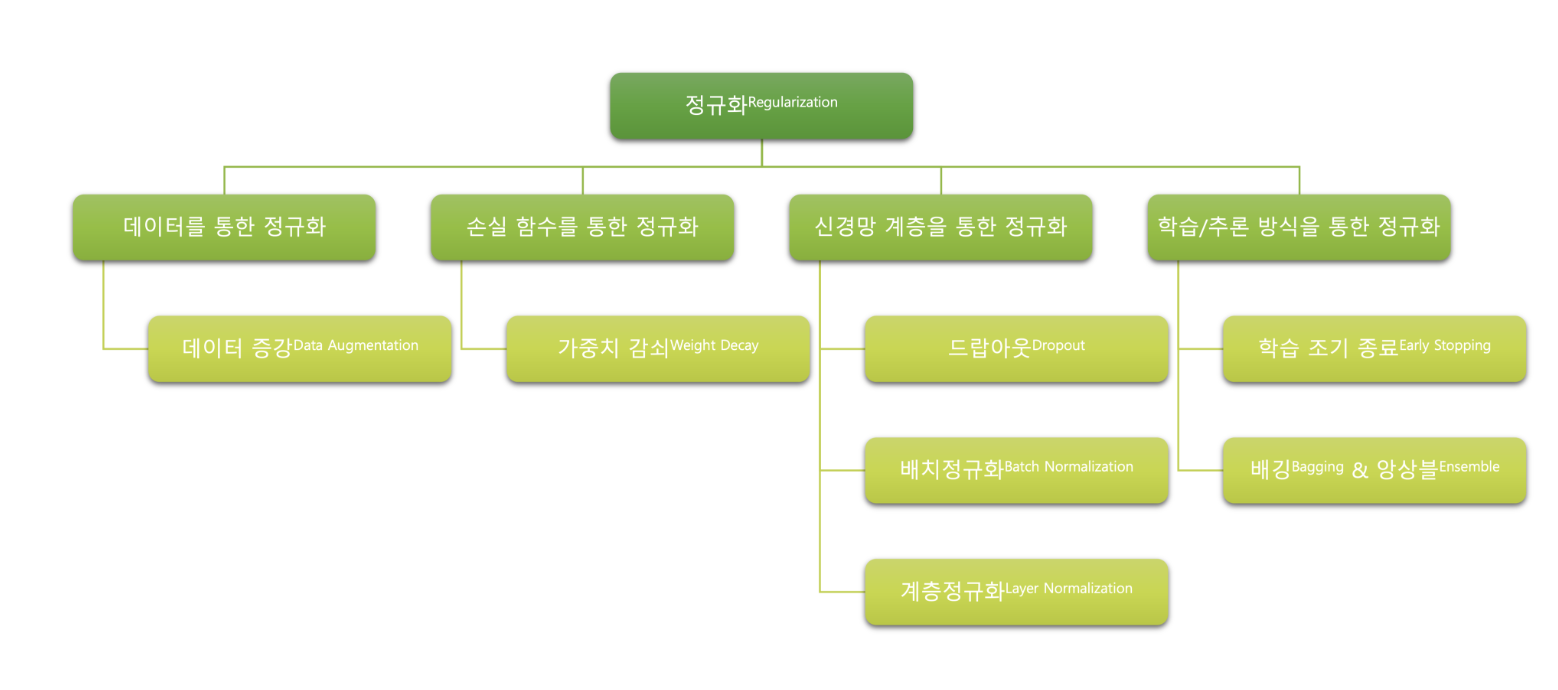

### 가중치 감쇠
가중치 파라미터가 학습되는 것을 방해하여 오버피팅을 방지하는 정규화 기법입니다.

가중치 파라미터의 $L2$ 노름과 기존의 손실 값을 동시에 최소화하도록 손실 함수가 수정되었습니다.

#### L1 노름의 사용
L1,L2 노름이 적용된 가중치 감쇠 정규화 기법이 적용되면 예전처럼 $W$에 가까이 다가가지 못하게 됩니다. 따라서 L1 노름을 활용하여 가중치 감쇠를 적용할 경우, 가중치 파라미터의 값들이 희소(sparse)하도록 제한합니다.

가중치 감쇠와 같은 정규화 기법은 보통 학습을 방해하는 형태를 취함으로써 오버피팅을 최소화하는 목적을 달성합니다.

### 데이터 증강(Data Augmentation)
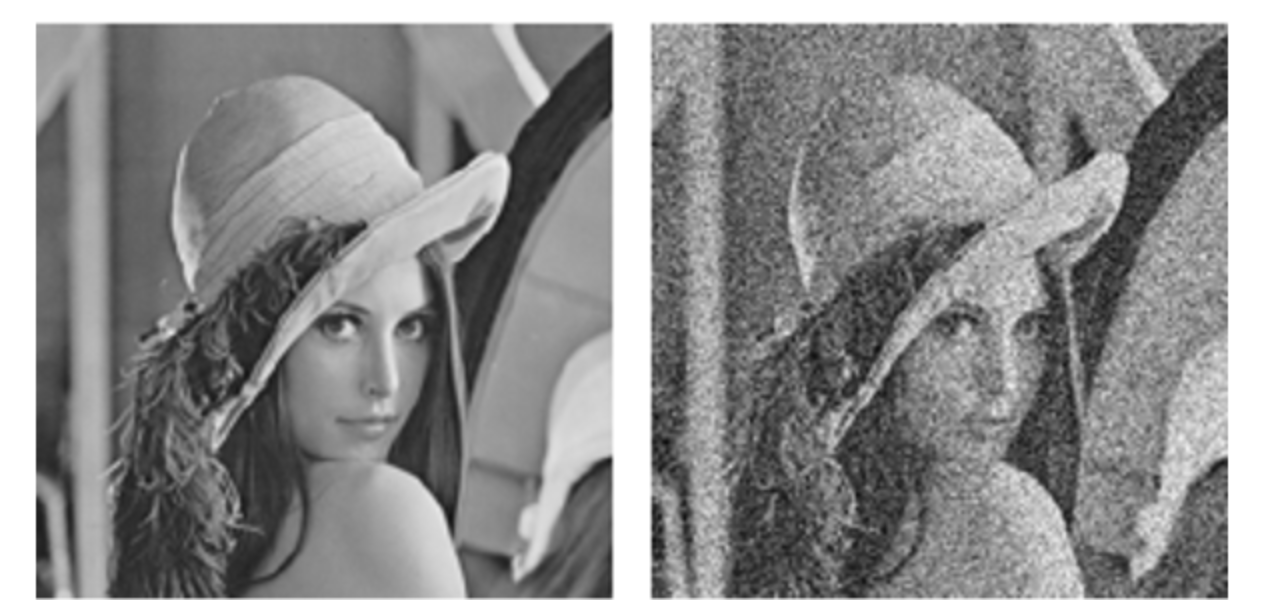

위의 그림과 같이 일부 노이즈가 추가되더라도 여전히 사람 눈에는 같은 이미지로 보이는 것처럼 컴퓨터도 두 이미지가 같다고 판단할 수 있어야 하기 때문에 굉장히 간단하면서도 효과적인 노이즈 추가 기법입니다.

노이즈 추가 과정에서 불필요한 특징들이 노이즈에 의해 제거되거나 변형될 수 있으며, 이로 인해 모델의 일반화 성능이 높아질 수 있습니다.

#### 회전과 이동,뒤집기

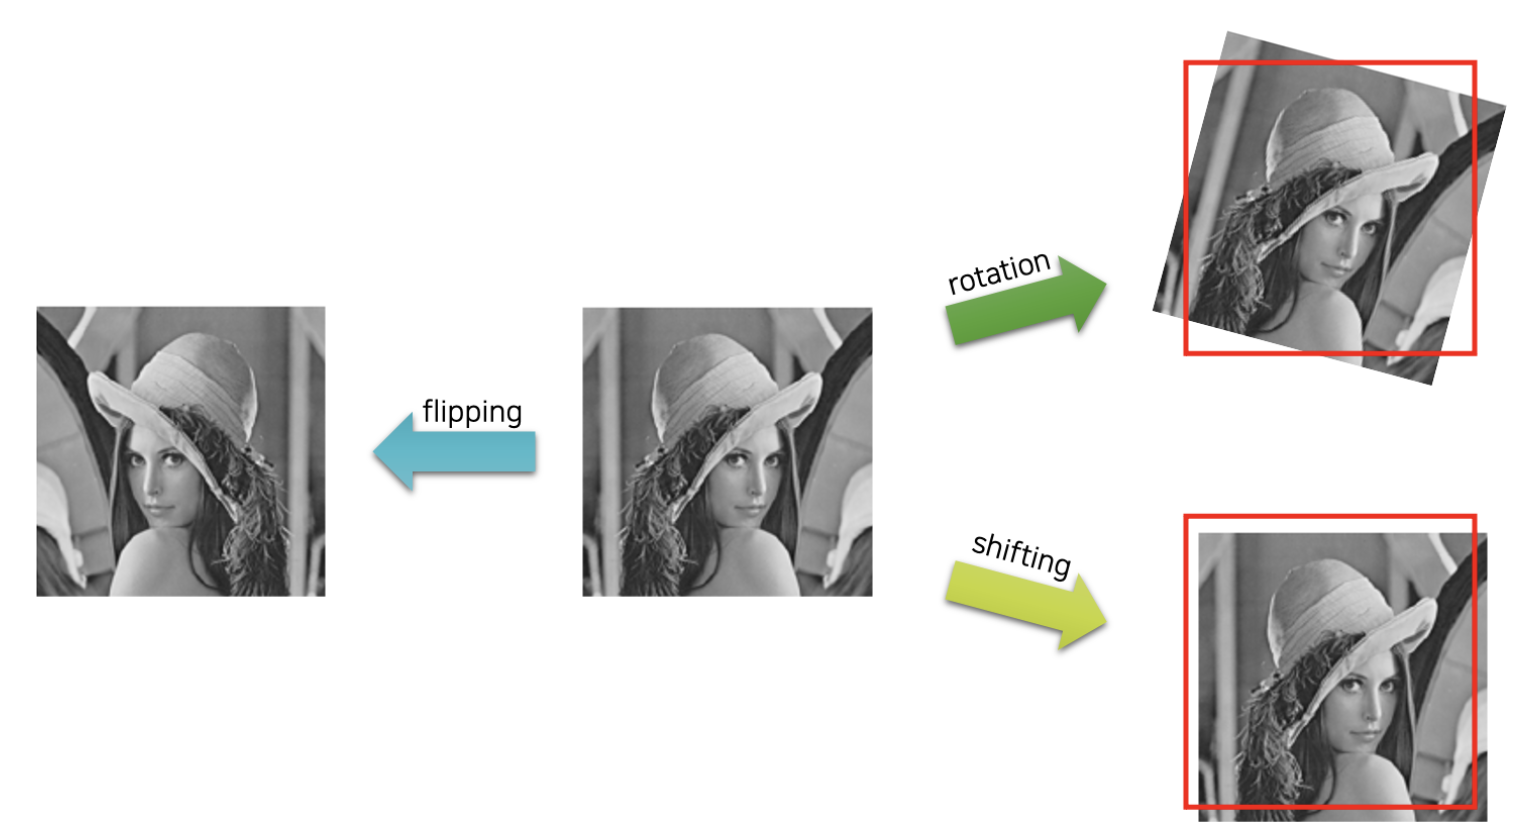

사람의 얼굴은 좌우 대칭이므로, 좌우 수평 뒤집기(flipping)기법은 얼굴 데이터 증강에 유용하게 활용될 수 있습니다.

### 생성 모델을 활용한 데이터 증강
생성 모델은 데이터셋의 분포 자체를 학습하여 모델로부터 데이터셋의 샘플과 유사한 샘플들을 생성해낼 수 있는 모델로 $GAN, autoencoder$가 대표적인 사례입니다.


### 데이터 증강의 장점과 한계
데이터 증강은 쉽게 데이터를 확장시킬 수 있고 신경망의 구조나 학습 기법의 수정 없이 정규화를 적용할 수 있습니다. 하지만 데이터를 증강한다는 것은 새로운 지식을 배우는 것이 아니라 오히려 최적화를 수월하게 수행할 수 있도록 도와주는 측면이 더 강하다고 볼 수 있습니다.

### 드롭아웃(drop out)
임의 노드를 일정 확률로 드롭해서 학습에 참여하지 않도록 하는 방법입니다.

데이터를 신경망에 통과시키는 과정에서 노드가 생략되므로 자연스럽게 역전파에서도 제외됩니다.
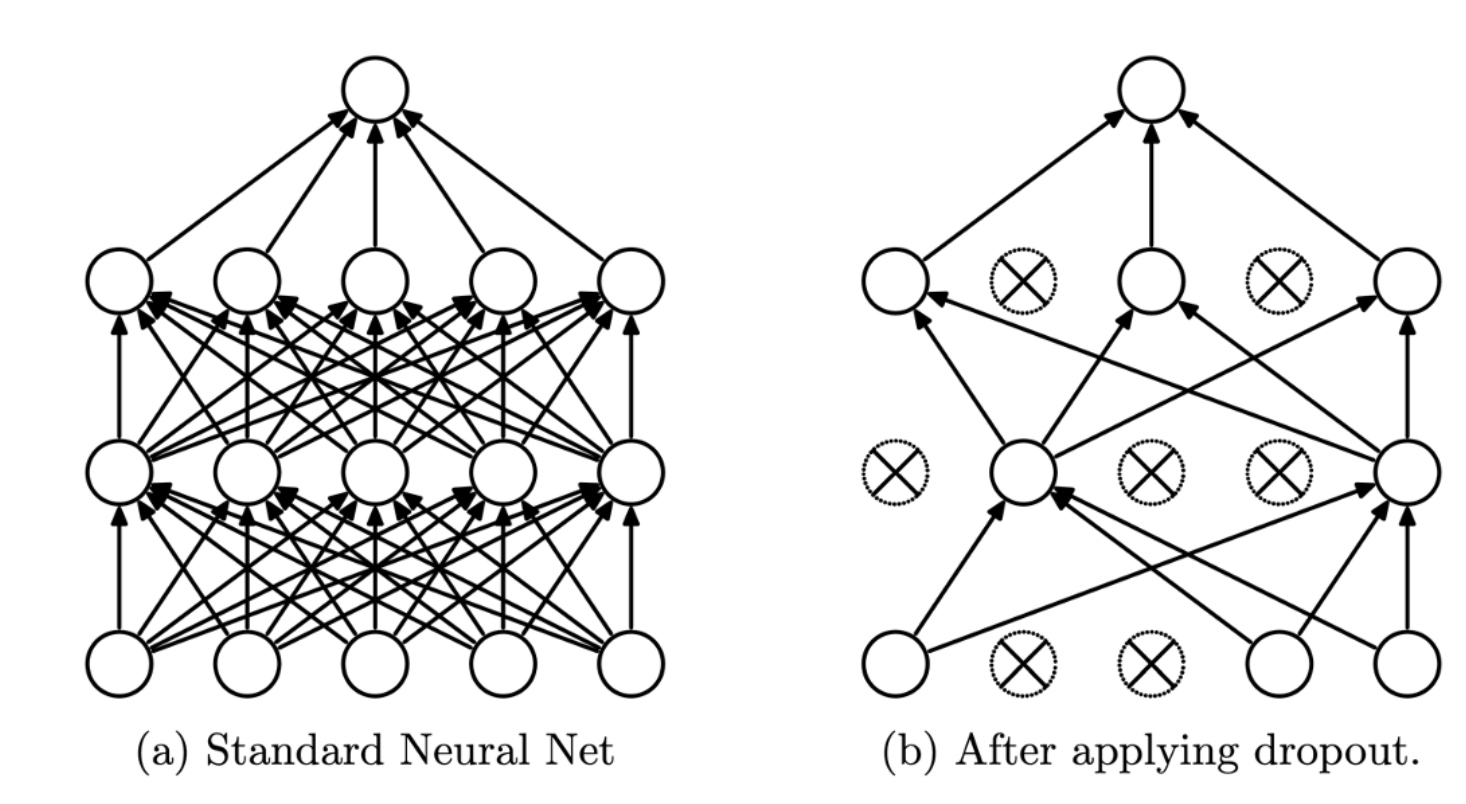

드롭아웃의 동작 방식은 <font color="orange">학습에서만 적용되는 방법</font>인데 추론(inference)에서는 드롭되는 노드 없이 모든 노드가 항상 추론에 참여합니다.

파이토치에서는 학습할 때에 $\frac{1}{1-p}$를 드롭아웃 계층 출력값에 곱해주도록 합니다.

드롭아웃은 이전까지 소개한 정규화 기법과 달리 신경망의 계층으로 구현될 수 있습니다. 파이토치에서는 미리 구현된 드롭아웃 계층을 제공하고 있습니다.
보통 드롭아웃이 구현되는 위치는 활성 함수와 다음 계층 사이가 됩니다.
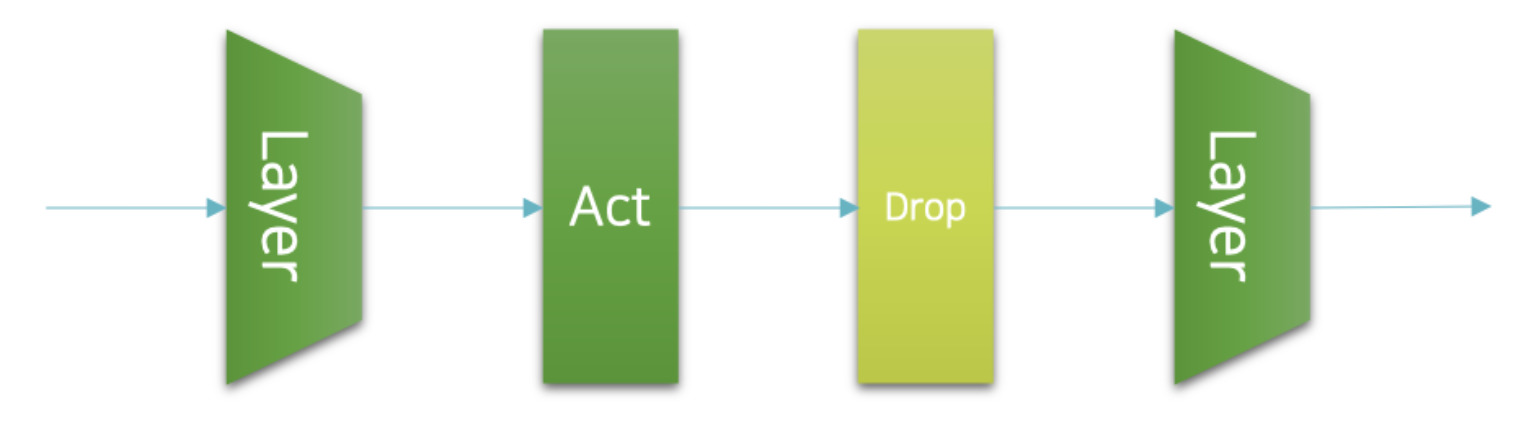

In [ ]:
### dropout example ###
import torch.nn as nn

p=0.3

model=nn.Sequetial(
    nn.Linear(input_dim,200),
    nn.ReLU(),
    nn.Dropout(p),
    nn.Linear(200,100),
    nn.ReLU(),
    nn.Dropout(p),
    nn.Linear(100,output_dim)
)

또한 추론과 학습이 다르게 동작하도록 해야 하기 떄문에 학습과 추론 코드에 추가적인 구현이 필요합니다.

파이토치의 $nn.Module$을 상속받은 클래스는 $train(),eval()$가 호출되면 해당 객체 안에 포함된 드롭아웃과 같이 학습과 추론에서 다르게 동작하는 계층들은 자동으로 학습 모드와 추론 모드로 전환됩니다.



In [ ]:
### dropout example ###
for epoch_idx in range(n_epochs):
  model.train()
  for iter_idx in range(n_train_iters):
    # Training produce
  model.eval()
  for iter_idx in range(n_valid_iters):
    #Validation procedure

### 드롭아웃의 한계

드롭아웃이 적용되면 비록 일반화 성능이 개선될 수는 있어도 손실 값의 수렴 속도가 저하될 수 있고 학습 오차가 증가할 수 있습니다.

### 배치정규화(Batch Normalization)
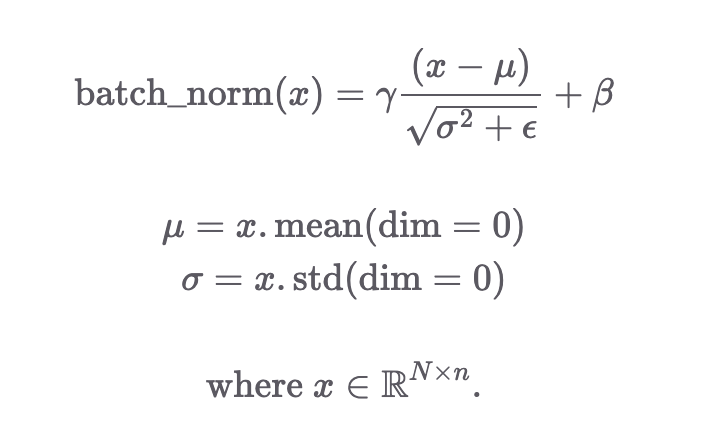

배치정규화 기법도 드롭아웃과 마찬가지로 학습과 추론에서의 동작 방식이 다릅니다.

배치정규화가 추론에서 동작이 다른 이유는 바로 미니배치의 평균과 표준편차를 구하는 방식 때문입니다.
매 신경망을 통과하는 미니배치마다 평균과 표준편차를 구하고, 이를 활용하여 표준정규분포화를 수행합니다.


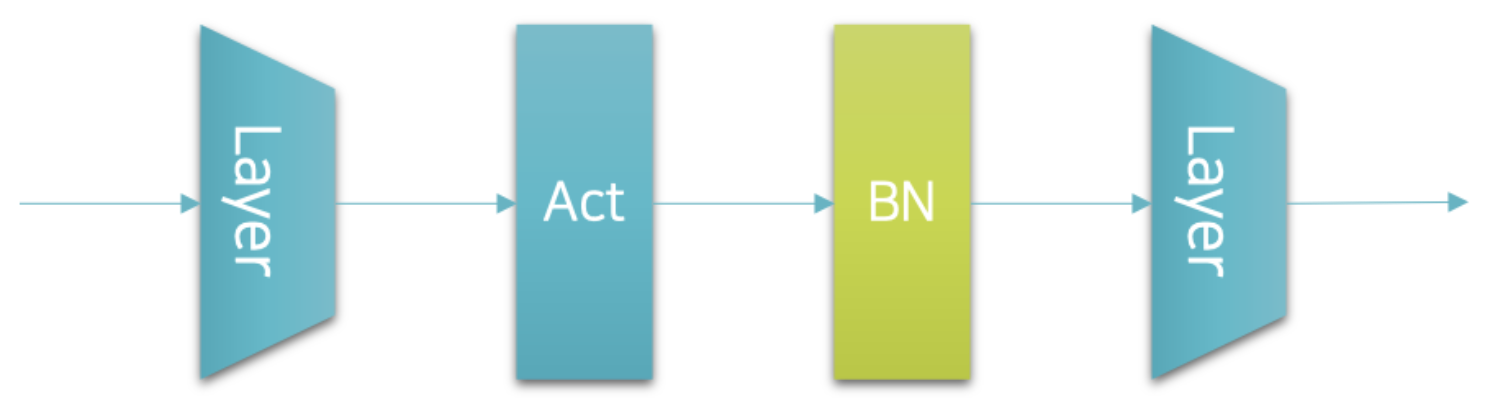

In [ ]:
### batchNormalize example ###
model=nn.Sequential(
    nn.Linear(input_dim,200),
    nn.ReLU(),
    nn.BatchNorm1d(200),
    nn.Linear(200,100),
    nn.ReLU(),
    nn.BatchNorm1d(100),
    nn.Linear(100,output_dim)

)

배치정규화 계층을 생성할 때의 파라미터 입력은 이전 계층으로부터 나온 출력 벡터의 크기를 넣어주면 됩니다.

### MNIST 데이터로 정규화 진행

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from copy import deepcopy
from torchvision import transforms,datasets

In [4]:
#데이터 불러오기
train=datasets.MNIST('./data',train=True,download=True,
                     transform=transforms.Compose([transforms.ToTensor()]))
test=datasets.MNIST('./data',train=False,
                     transform=transforms.Compose([transforms.ToTensor()]))


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.54MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.7MB/s]


In [5]:
train

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [6]:
test

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [7]:
# 데이터 정규화
X_data=train.data.float()/255.
y_data=train.targets

X_test=test.data.float()/255.
y_test=test.targets

In [8]:
# 28x28 이미지를 1차원으로 변환
X_data=X_data.view(X_data.size(0),-1)
X_test=X_test.view(X_test.size(0),-1)

print(X_data.size())
print(X_test.size())
print(y_data.size())
print(y_data.size())

torch.Size([60000, 784])
torch.Size([10000, 784])
torch.Size([60000])
torch.Size([60000])


In [9]:
# 데이터 분리
from sklearn.model_selection import train_test_split
X_train,X_valid,y_train,y_valid=train_test_split(X_data,y_data,test_size=0.2,random_state=5)
print(X_train.shape,X_valid.shape)
print(y_train.shape,y_valid.shape)

torch.Size([48000, 784]) torch.Size([12000, 784])
torch.Size([48000]) torch.Size([12000])


In [23]:
input_size=X_data.size(-1)
output_size=int(y_data.max())+1

print(input_size, output_size)

784 10


### 신경망 설계
정규화 계층을 간편하게 모델에 삽입하기 위해 $nn.Module$을 상속받은 클래스를 통해 서브 모듈을 정의하여 $nn.Sequential$에 반복하여 사용해봅시다.


- 선형 계층 + 비선형 활성화 함수 + 정규배치 계층으로 구성된 클래스 생성

- 배치정규화로 학습 안정화, 드롭아웃으로 과적합 방지를 해봅시다.

In [28]:
# 배치 계층
class LinearBatchAct(nn.Module):
  def __init__(self,input_dim,output_dim,use_batch_norm=True,dropout_p=0.5):
    super().__init__()
    self.input_dim=input_dim
    self.output_dim=output_dim
    self.use_batch_norm=use_batch_norm
    self.dropout_p=dropout_p

    # 정규배치를 하지 않는 경우엔 Dropout을 사용
    self.block=nn.Sequential(
        nn.Linear(input_dim,output_dim),
        nn.LeakyReLU(),
        nn.BatchNorm1d(output_dim) if use_batch_norm else nn.Dropout(dropout_p)

    )
  def forward(self,x):
    y=self.block(x)
    return y


In [26]:
class MyModel(nn.Module):
  def __init__(self,input_dim,output_dim,use_batch_norm=True,dropout_p=0.4):
    super().__init__()
    self.layers=nn.Sequential(
        LinearBatchAct(input_dim,500,use_batch_norm,dropout_p),
        LinearBatchAct(500,400,use_batch_norm,dropout_p),
        LinearBatchAct(400,300,use_batch_norm,dropout_p),
        LinearBatchAct(300,200,use_batch_norm,dropout_p),
        LinearBatchAct(200,100, use_batch_norm,dropout_p),
        LinearBatchAct(100,50, use_batch_norm,dropout_p),

        nn.Linear(50,output_dim),
        nn.LogSoftmax(dim=1)


  )
  def forward(self,x):
    y=self.layers(x)
    return y

In [ ]:
# 배치정규화와 드롭아웃 동시에 적용
# class Model(nn.Module):
#     def __init__(self, input_dim, output_dim, dropout_p=0.4):
#         super().__init__()

#         self.layers = nn.Sequential(
#             nn.Linear(input_dim, 500),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(500),
#             nn.Dropout(dropout_p),

#             nn.Linear(500, 400),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(400),
#             nn.Dropout(dropout_p),

#             nn.Linear(400, 300),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(300),
#             nn.Dropout(dropout_p),

#             nn.Linear(300, 200),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(200),
#             nn.Dropout(dropout_p),

#             nn.Linear(200, 100),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(100),
#             nn.Dropout(dropout_p),

#             nn.Linear(100, 50),
#             nn.LeakyReLU(),
#             nn.BatchNorm1d(50),
#             nn.Dropout(dropout_p),

#             nn.Linear(50, output_dim),
#             nn.LogSoftmax(dim=1)
#         )

#     def forward(self, x):
#         return self.layers(x)

In [29]:
model=MyModel(input_size,output_size)

In [37]:
optimizer=optim.Adam(model.parameters())
loss_func=nn.NLLLoss()

모델과 텐서를 gpu 디바이스로 이동 및 복사

In [30]:
device=torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

In [31]:
model=model.to(device)

X_train=X_train.to(device)
X_valid=X_valid.to(device)
X_test=X_test.to(device)

y_train=y_train.to(device)
y_valid=y_valid.to(device)
y_test=y_test.to(device)

In [32]:
# 학습파라미터 설정
n_epochs=10000
batch_size=256
print_interval=10

lowest_epoch=np.inf
lowest_loss=np.inf
best_model=None
early_stop=50

In [34]:
from tqdm import tqdm

In [48]:
# 학습 구현
train_history,val_history=[],[]

for i in tqdm(range(n_epochs)):
  # 훈련모드로 실행
  model.train()

  indices=torch.randperm(X_train.size(0)).to(device)

  X_=torch.index_select(X_train,dim=0,index=indices)
  y_=torch.index_select(y_train,dim=0,index=indices)

  X_=X_.split(batch_size,dim=0)
  y_=y_.split(batch_size,dim=0)

  train_loss,val_loss=0,0
  pred_y=[]
  # 훈련
  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    # 크기가  1인 차원을 삭제(1차원으로 변경)
    loss=loss_func(pred_y_i,y_i.squeeze())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += float(loss)
  train_loss=train_loss/len(X_)

  # 검증
  model.eval()
  with torch.no_grad():
    X_=X_valid.split(batch_size,dim=0)
    y_=y_valid.split(batch_size,dim=0)

    for X_i,y_i in zip(X_,y_):
      # pred_y_i.shape=[64,클래스 예측값]
      pred_y_i=model(X_i)
      # 정답레이블 shape은 [64]라서 shape에 맞추기 위해 squeeze() 사용!
      loss=loss_func(pred_y_i,y_i.squeeze())
      val_loss += loss
      pred_y.append(pred_y_i)
    val_loss =val_loss/len(X_)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if (i+1) % print_interval == 0:
      print(f"Epoch {i+1} : train_loss:{train_loss:.4e}\
      valid_loss:{val_loss:.4e}, lowest_loss:{lowest_loss:.4e}")

    if val_loss <lowest_loss:
      lowest_loss=val_loss
      lowest_epoch = i
      best_model = deepcopy(model.state_dict())

    else:
      if i>0 and lowest_epoch + early_stop < i+1:
        print(f"early_stop:{early_stop}")
        break

print(f"{lowest_epoch + 1} epoch에서 가장 낮은 검증 손실값:{lowest_loss:.4e}")
# 가장 손실값이 낮을 때의 w,b 를 저장해서 model에 초기화
model.load_state_dict(best_model)


  0%|          | 10/10000 [00:08<2:10:18,  1.28it/s]

Epoch 10 : train_loss:9.1160e-03      valid_loss:8.1739e-02, lowest_loss:6.0637e-02


  0%|          | 20/10000 [00:16<2:23:16,  1.16it/s]

Epoch 20 : train_loss:6.1554e-03      valid_loss:8.0305e-02, lowest_loss:6.0637e-02


  0%|          | 30/10000 [00:24<2:06:10,  1.32it/s]

Epoch 30 : train_loss:4.6243e-03      valid_loss:7.2191e-02, lowest_loss:6.0637e-02


... (7 outputs left out)

Epoch 70 : train_loss:1.4729e-03      valid_loss:7.8541e-02, lowest_loss:6.0637e-02


  1%|          | 70/10000 [00:57<2:16:16,  1.21it/s]

early_stop:50
21 epoch에서 가장 낮은 검증 손실값:6.0637e-02


<All keys matched successfully>

/tmp/ipykernel_330/3175545061.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


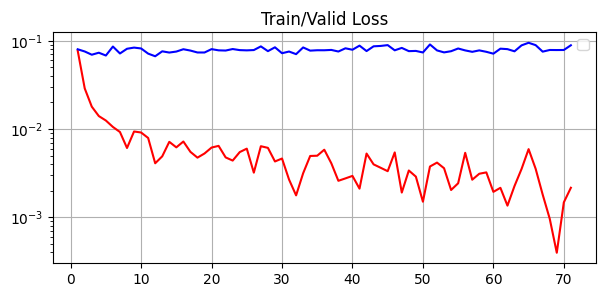

In [49]:
# 손실곡선 확인
val_loss_list=[v.cpu().item() for v in val_history]

plt.figure(figsize=(7,3))
plt.grid()
plt.title('Train/Valid Loss')
plt.plot(range(1,len(train_history)+1),train_history,color="r")
plt.plot(range(1,len(val_loss_list)+1),val_loss_list,color="b")
plt.legend()
plt.yscale('log')
plt.show()

In [54]:
# 결과 확인
test_loss=0
pred_y=[]

with torch.no_grad():
  X_=X_test.split(batch_size,dim=0)
  y_=y_test.split(batch_size,dim=0)

  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    loss=loss_func(pred_y_i,y_i.squeeze())
    pred_y.append(pred_y_i)
    test_loss += float(loss)
  test_loss=test_loss / len(X_)
  pred_y=torch.cat(pred_y,dim=0)
  print(f'Test loss:{test_loss:.4e}')

Test loss:7.2295e-02


- 이전 결과와 비교하기
  - ERR (Error Reduction Raw)로 상대적인 모델의 개선 폭을 측정합시다.

<center>  
<img src="https://arome1004.cafe24.com/images/pytorch/lecture_image/07_err.png" width=30%>
</center>

In [55]:
# 검증 데이터로 검증한 이전 손실함수 비교
valid_loss=6.0637e-02
err=(1-valid_loss)-(1-test_loss)/(1-valid_loss)
err

-0.04822688232159933

In [57]:
from sklearn.metrics import confusion_matrix
pd.DataFrame(confusion_matrix(y_test.cpu(),torch.argmax(pred_y.cpu(),dim=1)),
             columns = [f'pred_{i}'for i in range(10)],
             index = [f'true_{i}'for i in range(10)]
             )

,pred_0,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7,pred_8,pred_9
true_0,974,1,0,0,0,1,1,0,1,2
true_1,0,1124,2,1,0,3,3,1,1,0
true_2,1,1,1013,2,3,0,2,7,3,0
true_3,0,0,4,996,0,2,0,3,3,2
true_4,1,0,2,0,957,1,5,2,1,13
true_5,1,0,0,12,1,867,1,2,4,4
true_6,3,2,0,1,1,3,942,0,6,0
true_7,1,3,9,2,2,0,0,1004,3,4
true_8,2,0,2,4,0,1,1,3,958,3
true_9,0,2,1,4,6,2,0,5,4,985


DNN 이미지 분석
- DNN 신경망을 이미지 처리에 사용한다면 이미지의 위치에 민감하게 동작하며 위치에 종속적인 결과를 얻게됨(모든 픽셀을 연산하기 떄문)
- DNN은 아래 세 개의 7은 패턴이 다르다고 판단
- <font color="orange">DNN은 특징을 추출하지 못함!</font>
- 특징을 추출하는 특성추출부가 있는  CNN을 사용하자!